# 05 - Exploration visuelle et avant / après

On lit les trois tables gold et on les **regarde** : distribution, classement, tendance, puis le graphique qui répond à Claire (activité contre prix). La dernière partie compare un graphique **naïf** et sa version **corrigée**, chaque correction étant rattachée à un principe de perception.


In [1]:
import os
import sys
sys.path.append("/home/jovyan/work")

import matplotlib.pyplot as plt
import pandas as pd

from outils.source import creer_session, LAKE

GOLD = f"{LAKE}/gold"
FIGURES = "/home/jovyan/work/docs/figures"
os.makedirs(FIGURES, exist_ok=True)

# Les tables gold sont petites : on les charge dans pandas puis on libère Spark
spark = creer_session("exploration")
dep = spark.read.format("delta").load(f"{GOLD}/gold_departement").toPandas()
mois = spark.read.format("delta").load(f"{GOLD}/gold_departement_mois").toPandas()
nat = spark.read.format("delta").load(f"{GOLD}/gold_national_mois").toPandas()
spark.stop()

print(dep.shape, mois.shape, nat.shape)

Spark 4.2.0 (Hadoop 3.5.0) + Delta Lake + data lake S3. Le premier démarrage télécharge des jars : plusieurs minutes.
Session prête.
(291, 9) (3492, 9) (36, 5)


## 1. Les chiffres du niveau « Tous »

In [2]:
tous = dep[dep["type_bien"] == "Tous"].copy()
tous[["nb_ventes", "prix_m2_median", "ecart_national"]].describe().round(2)

,nb_ventes,prix_m2_median,ecart_national
count,97.00,97.00,97.00
mean,8296.94,2393.86,-0.08
std,6643.67,1228.46,0.47
min,741.00,1016.00,-0.61
25%,3267.00,1589.00,-0.39
50%,6640.00,2053.00,-0.22
75%,11197.00,2840.00,0.09
max,29894.00,9726.00,2.72


## 2. Combien de ventes par département ?

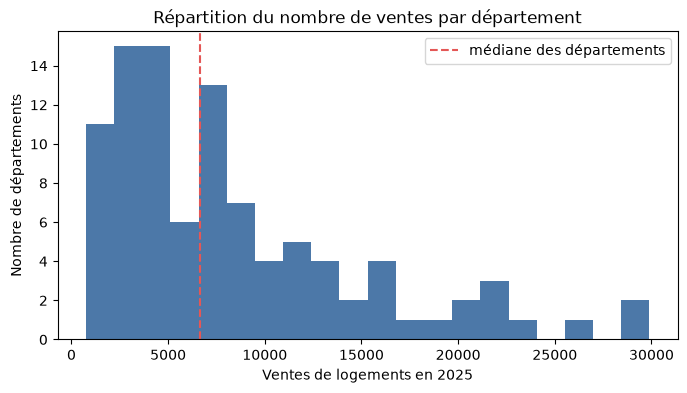

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(tous["nb_ventes"], bins=20, color="#4C78A8")
ax.axvline(tous["nb_ventes"].median(), color="#E45756", linestyle="--", label="médiane des départements")
ax.set_xlabel("Ventes de logements en 2025")
ax.set_ylabel("Nombre de départements")
ax.set_title("Répartition du nombre de ventes par département")
ax.legend()
plt.show()

## 3. Les départements les moins chers et les plus chers (prix au m² médian)

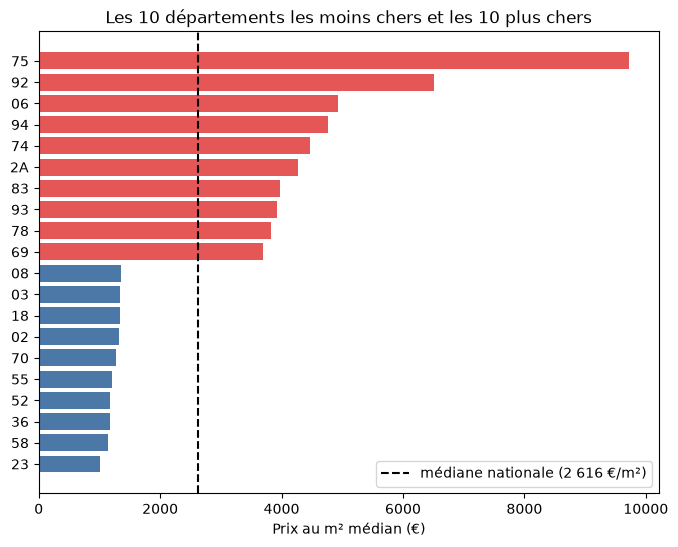

In [4]:
classement = tous.sort_values("prix_m2_median")
extremes = pd.concat([classement.head(10), classement.tail(10)])
national = tous["prix_m2_median_national"].iloc[0]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(extremes["code_departement"], extremes["prix_m2_median"], color=["#4C78A8"] * 10 + ["#E45756"] * 10)
ax.axvline(national, color="black", linestyle="--", label=f"médiane nationale ({national:,.0f} €/m²)".replace(",", " "))
ax.set_xlabel("Prix au m² médian (€)")
ax.set_title("Les 10 départements les moins chers et les 10 plus chers")
ax.legend()
plt.show()

## 4. La tendance nationale mois par mois

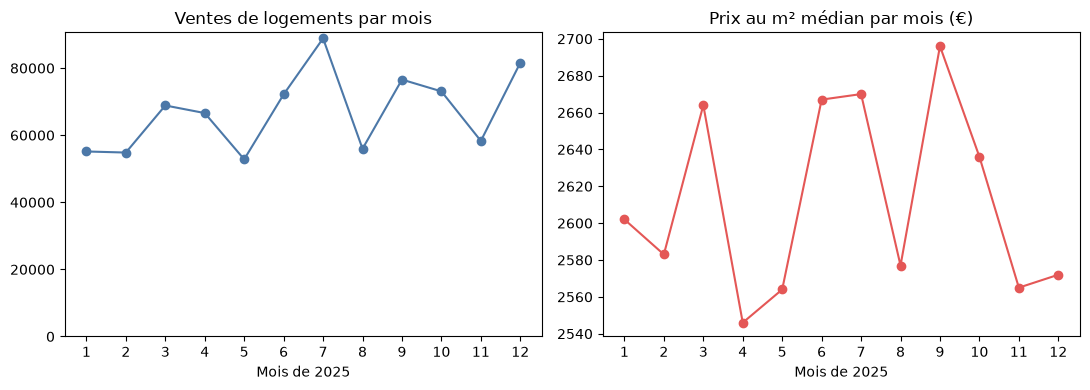

In [5]:
n = nat[nat["type_bien"] == "Tous"].sort_values("mois")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(n["mois"], n["nb_ventes"], marker="o", color="#4C78A8")
a1.set_ylim(bottom=0)
a1.set_title("Ventes de logements par mois")
a2.plot(n["mois"], n["prix_m2_median"], marker="o", color="#E45756")
a2.set_title("Prix au m² médian par mois (€)")
for a in (a1, a2):
    a.set_xticks(range(1, 13))
    a.set_xlabel("Mois de 2025")
plt.tight_layout()
plt.show()

## 5. Le graphique de la décision : activité contre prix
Chaque point est un département. À droite : plus de ventes que la **médiane des départements** (c'est un choix de définition de « actif », à justifier). En bas : un prix au m² **inférieur** à la médiane nationale (« accessible »).

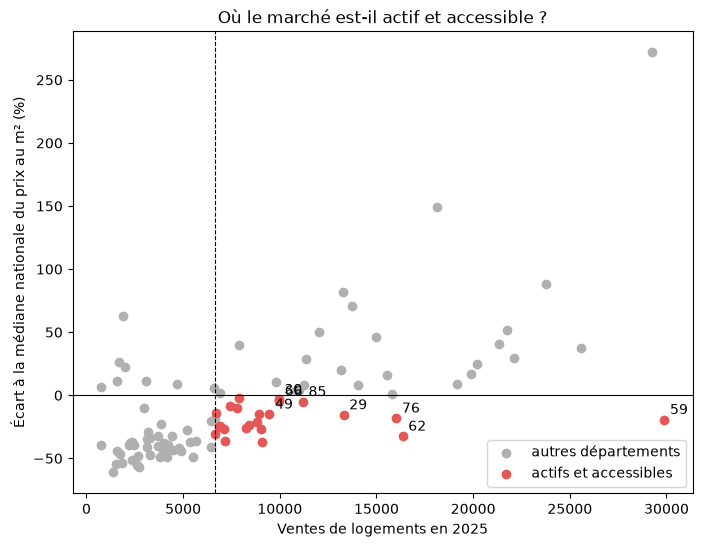

23 départements actifs et accessibles


In [6]:
seuil_actif = tous["nb_ventes"].median()
choisis = (tous["nb_ventes"] > seuil_actif) & (tous["ecart_national"] < 0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(tous.loc[~choisis, "nb_ventes"], tous.loc[~choisis, "ecart_national"] * 100, color="#B0B0B0", label="autres départements")
ax.scatter(tous.loc[choisis, "nb_ventes"], tous.loc[choisis, "ecart_national"] * 100, color="#E45756", label="actifs et accessibles")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(seuil_actif, color="black", linewidth=0.8, linestyle="--")
for _, r in tous[choisis].nlargest(8, "nb_ventes").iterrows():
    ax.annotate(r["code_departement"], (r["nb_ventes"], r["ecart_national"] * 100), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Ventes de logements en 2025")
ax.set_ylabel("Écart à la médiane nationale du prix au m² (%)")
ax.set_title("Où le marché est-il actif et accessible ?")
ax.legend()
plt.show()
print(choisis.sum(), "départements actifs et accessibles")

## 6. Avant / après

**Question posée au graphique :** *où se concentrent les ventes de logements ?*

### Avant : la version naïve
Un camembert de la part de chaque département dans le nombre de ventes.

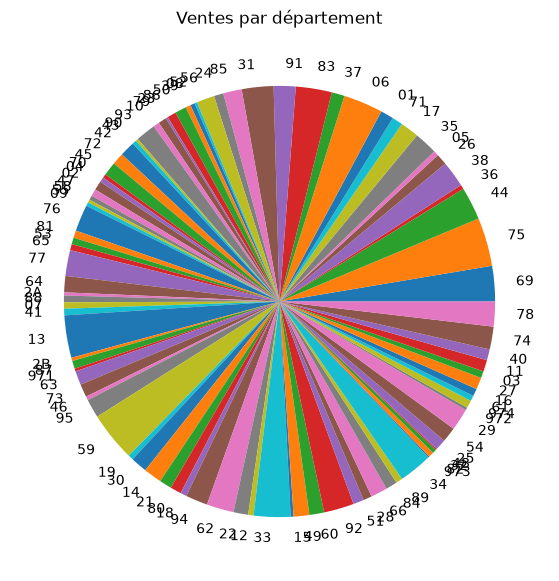

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(tous["nb_ventes"], labels=tous["code_departement"])
ax.set_title("Ventes par département")
fig.savefig(f"{FIGURES}/avant.png", dpi=150, bbox_inches="tight")
plt.show()

**Ce qui ne va pas :** 97 parts, des couleurs qui se répètent, des étiquettes qui se chevauchent, aucun ordre, aucune valeur lisible, un titre qui ne dit rien. On ne peut ni comparer deux départements, ni dire lequel domine.

### Après : la version corrigée
Les 15 premiers départements, triés, en barres horizontales, avec un titre qui donne le message.

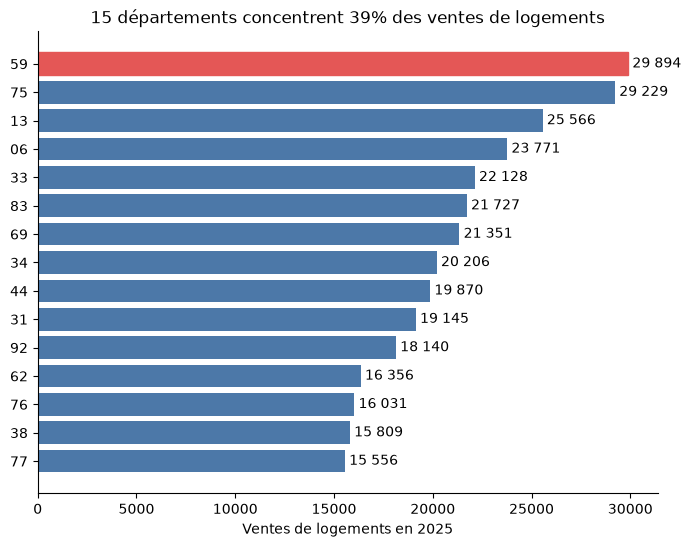

In [8]:
top = tous.nlargest(15, "nb_ventes").sort_values("nb_ventes")
part = top["nb_ventes"].sum() / tous["nb_ventes"].sum()

fig, ax = plt.subplots(figsize=(8, 6))
barres = ax.barh(top["code_departement"], top["nb_ventes"], color="#4C78A8")
barres[-1].set_color("#E45756")                                  # le premier est mis en évidence
ax.bar_label(barres, labels=[f"{v:,}".replace(",", " ") for v in top["nb_ventes"]], padding=3)
for bord in ("top", "right"):
    ax.spines[bord].set_visible(False)
ax.set_xlabel("Ventes de logements en 2025")
ax.set_title(f"15 départements concentrent {part:.0%} des ventes de logements")
fig.savefig(f"{FIGURES}/apres.png", dpi=150, bbox_inches="tight")
plt.show()

### Chaque correction et le principe de perception qui la justifie


| Correction | Avant | Après | Principe |
|---|---|---|---|
| Camembert remplacé par des barres | on compare des **angles** et des **aires** | on compare des **longueurs** sur une échelle commune | la position et la longueur sur une échelle commune sont les canaux que l'œil décode le plus précisément ; les angles et les aires le sont beaucoup moins |
| Tri par valeur | ordre arbitraire (code de département) | du plus grand au plus petit | l'ordre rend le classement immédiat (continuité, rang) |
| 97 parts réduites à 15 | impossible de lire 97 parts | 15 barres lisibles | limiter la quantité d'information à ce que l'œil peut traiter ; le reste est un détail |
| Une couleur + un accent | une teinte par part, répétées | une seule teinte, la première en rouge | la teinte distingue des catégories ; ici elle ne dit rien. Une couleur unique avec un seul accent guide l'attention (attribut pré-attentif) |
| Valeurs écrites au bout des barres | aucune valeur lisible | étiquetage direct | réduit l'effort de mise en correspondance entre le graphique et la légende (proximité) |
| Bordures et grille retirées | cadre complet | cadre allégé | réduire l'encre non informative (ratio données / encre) |
| Titre-message | « Ventes par département » | « 15 départements concentrent X % des ventes » | le titre énonce ce qu'il faut voir |

Les deux images sont enregistrées dans `docs/figures/` (`avant.png`, `apres.png`)